# US Accidents — Time Features & Their Relations

This notebook focuses **only on time**: which columns of the dataset describe time, which new
time features can be derived from them, and how those time features relate to the other
groups of features (Severity, Weather, Day/Night, Duration & Distance, Location, Road features).

Data: `US_Accidents_2000_sample.csv` (a representative 2,000-row stratified sample of the full dataset).

**Contents**
1. Setup & data loading
2. Time-related features (original + derived)
3. Time ↔ Severity
4. Time ↔ Weather
5. Time ↔ Day / Night & twilight
6. Time ↔ Duration & Distance
7. Time ↔ Location (State, Timezone)
8. Time ↔ Road features
9. Key findings

## 1. Setup & Data Loading

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 13
pd.set_option("display.max_columns", 60)

df = pd.read_csv("US_Accidents_2000_sample.csv")
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")

Rows: 2,000   Columns: 46


## 2. Time-Related Features

### 2.1 Original time-related columns
| Column | Meaning |
|---|---|
| `Start_Time` | Local start time of the accident |
| `End_Time` | Local time when the accident's impact on traffic flow ended |
| `Weather_Timestamp` | Time of the weather observation attached to the record |
| `Timezone` | Timezone of the accident location (the times above are in this local zone) |
| `Sunrise_Sunset` | Day / Night based on sunrise–sunset at that time and place |
| `Civil_Twilight` | Day / Night based on civil twilight |
| `Nautical_Twilight` | Day / Night based on nautical twilight |
| `Astronomical_Twilight` | Day / Night based on astronomical twilight |

### 2.2 Derived time features
From the timestamps we derive calendar and clock features that are easier to relate to other variables.

In [2]:
for c in ["Start_Time", "End_Time", "Weather_Timestamp"]:
    df[c] = pd.to_datetime(df[c], format="mixed", errors="coerce")

WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
SEASONS = ["Winter", "Spring", "Summer", "Autumn"]
TOD = ["Night (0-5)", "Morning (6-11)", "Afternoon (12-17)", "Evening (18-23)"]
SEV_COLORS = {1: "#2a9d8f", 2: "#e9c46a", 3: "#f4a261", 4: "#e63946"}
TWILIGHT_COLS = ["Sunrise_Sunset", "Civil_Twilight", "Nautical_Twilight", "Astronomical_Twilight"]
ROAD_COLS = ["Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit", "Railway",
             "Roundabout", "Station", "Stop", "Traffic_Calming", "Traffic_Signal", "Turning_Loop"]

st = df["Start_Time"]
df["Year"] = st.dt.year
df["Quarter"] = st.dt.quarter
df["Month"] = st.dt.month
df["Month_Name"] = pd.Categorical(st.dt.month.map(dict(enumerate(MONTHS, 1))), MONTHS, ordered=True)
df["Season"] = pd.Categorical(st.dt.month.map({12: "Winter", 1: "Winter", 2: "Winter",
                                                3: "Spring", 4: "Spring", 5: "Spring",
                                                6: "Summer", 7: "Summer", 8: "Summer",
                                                9: "Autumn", 10: "Autumn", 11: "Autumn"}),
                              SEASONS, ordered=True)
df["Weekday"] = pd.Categorical(st.dt.day_name(), WEEKDAYS, ordered=True)
df["Day_Type"] = np.where(st.dt.dayofweek >= 5, "Weekend", "Weekday")
df["Hour"] = st.dt.hour
df["Time_of_Day"] = pd.Categorical(pd.cut(df["Hour"], [-1, 5, 11, 17, 23], labels=TOD), TOD, ordered=True)
df["Rush_Hour"] = np.where((df["Day_Type"] == "Weekday") & df["Hour"].isin([7, 8, 9, 16, 17, 18]),
                           "Rush hour", "Off-peak")
df["Duration_min"] = (df["End_Time"] - df["Start_Time"]).dt.total_seconds() / 60
df["Weather_Lag_min"] = (df["Weather_Timestamp"] - df["Start_Time"]).dt.total_seconds() / 60
df["High_Severity"] = (df["Severity"] >= 3).astype(int)   # Severity 3 or 4

DERIVED = ["Year", "Quarter", "Month", "Month_Name", "Season", "Weekday", "Day_Type", "Hour",
           "Time_of_Day", "Rush_Hour", "Duration_min", "Weather_Lag_min"]
ORIG_TIME = ["Start_Time", "End_Time", "Weather_Timestamp", "Timezone"] + TWILIGHT_COLS

summary = pd.DataFrame({
    "kind": ["original"] * len(ORIG_TIME) + ["derived"] * len(DERIVED),
    "dtype": df[ORIG_TIME + DERIVED].dtypes.astype(str).values,
    "missing_%": (df[ORIG_TIME + DERIVED].isna().mean() * 100).round(2).values,
    "unique": df[ORIG_TIME + DERIVED].nunique().values,
    "example": df[ORIG_TIME + DERIVED].iloc[0].astype(str).values,
}, index=ORIG_TIME + DERIVED)
summary

,kind,dtype,missing_%,unique,example
Start_Time,original,datetime64[ns],0.00,2000,2016-07-19 10:53:47
End_Time,original,datetime64[ns],0.00,2000,2016-07-19 11:23:47
Weather_Timestamp,original,datetime64[us],1.65,1953,2016-07-19 10:53:00
Timezone,original,str,0.05,4,US/Pacific
Sunrise_Sunset,original,str,0.50,2,Day
Civil_Twilight,original,str,0.50,2,Day
Nautical_Twilight,original,str,0.50,2,Day
Astronomical_Twilight,original,str,0.50,2,Day
Year,derived,int32,0.00,8,2016
Quarter,derived,int32,0.00,4,3


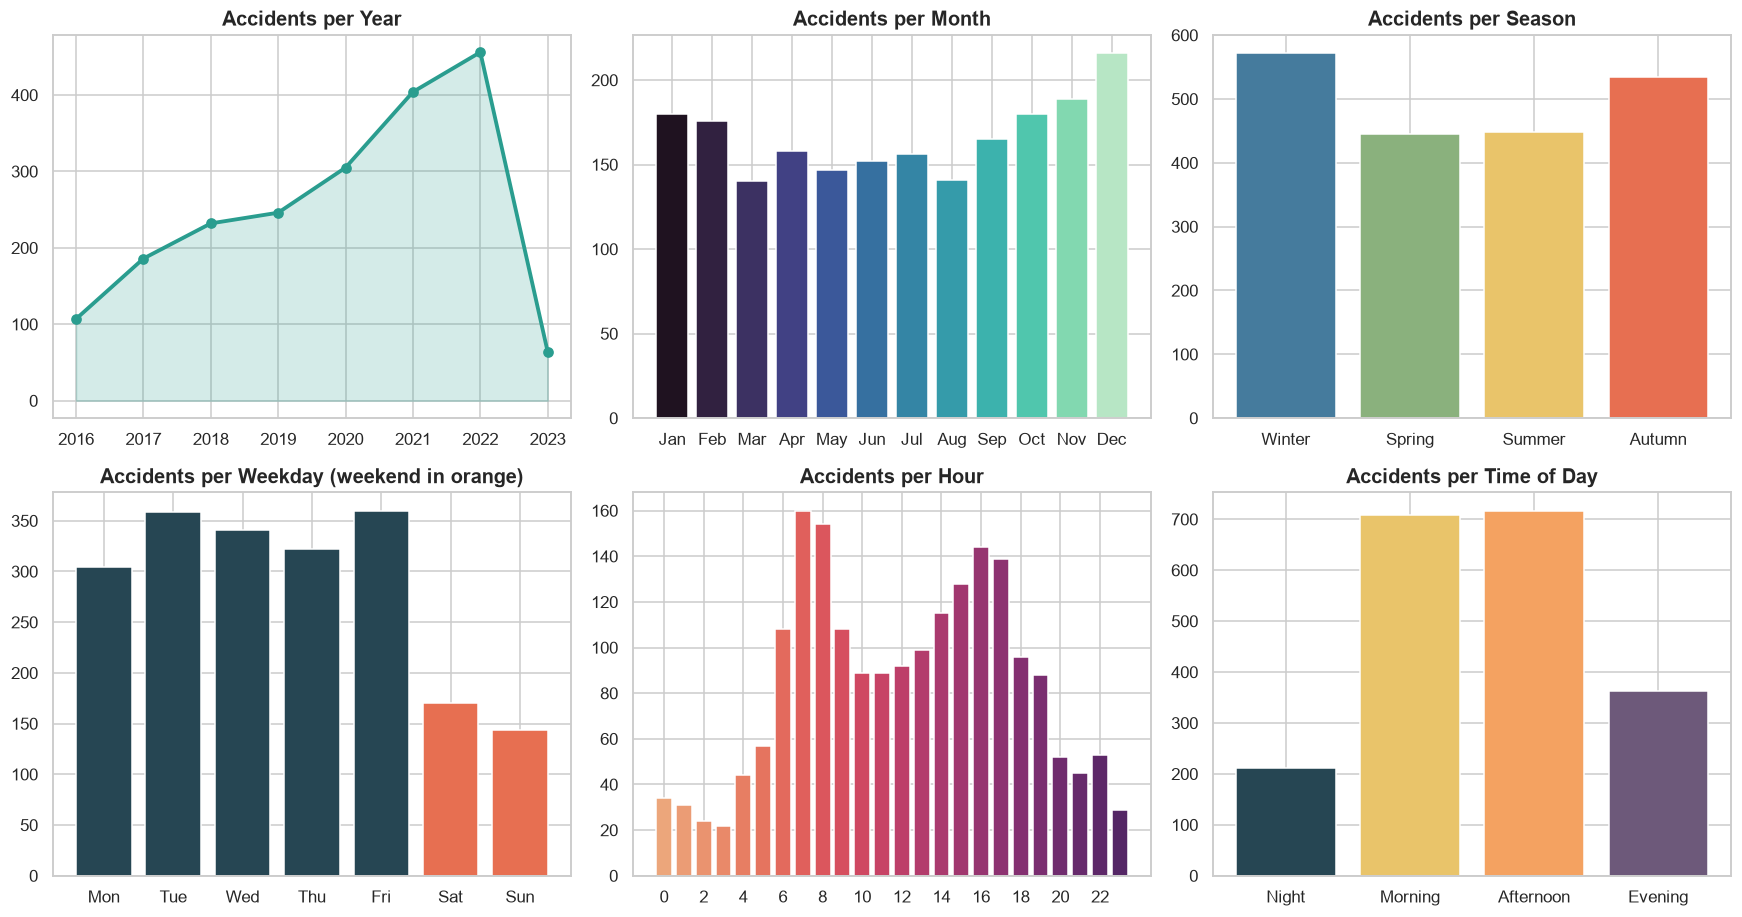

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
yr = df["Year"].value_counts().sort_index()
axes[0, 0].plot(yr.index, yr.values, marker="o", lw=2.5, color="#2a9d8f")
axes[0, 0].fill_between(yr.index, yr.values, alpha=.2, color="#2a9d8f")
axes[0, 0].set_title("Accidents per Year")

mo = df["Month_Name"].value_counts().reindex(MONTHS)
axes[0, 1].bar(mo.index, mo.values, color=sns.color_palette("mako", 12))
axes[0, 1].set_title("Accidents per Month")

se = df["Season"].value_counts().reindex(SEASONS)
axes[0, 2].bar(se.index, se.values, color=["#457b9d", "#8ab17d", "#e9c46a", "#e76f51"])
axes[0, 2].set_title("Accidents per Season")

wd = df["Weekday"].value_counts().reindex(WEEKDAYS)
axes[1, 0].bar([d[:3] for d in wd.index], wd.values, color=["#264653"] * 5 + ["#e76f51"] * 2)
axes[1, 0].set_title("Accidents per Weekday (weekend in orange)")

hr = df["Hour"].value_counts().reindex(range(24), fill_value=0)
axes[1, 1].bar(hr.index, hr.values, color=sns.color_palette("flare", 24))
axes[1, 1].set_title("Accidents per Hour"); axes[1, 1].set_xticks(range(0, 24, 2))

td = df["Time_of_Day"].value_counts().reindex(TOD)
axes[1, 2].bar([t.split(" ")[0] for t in td.index], td.values, color=["#264653", "#e9c46a", "#f4a261", "#6d597a"])
axes[1, 2].set_title("Accidents per Time of Day")
plt.tight_layout(); plt.show()

## 3. Time ↔ Severity
How the mix of severity levels changes with the hour, the day, the month and the year.

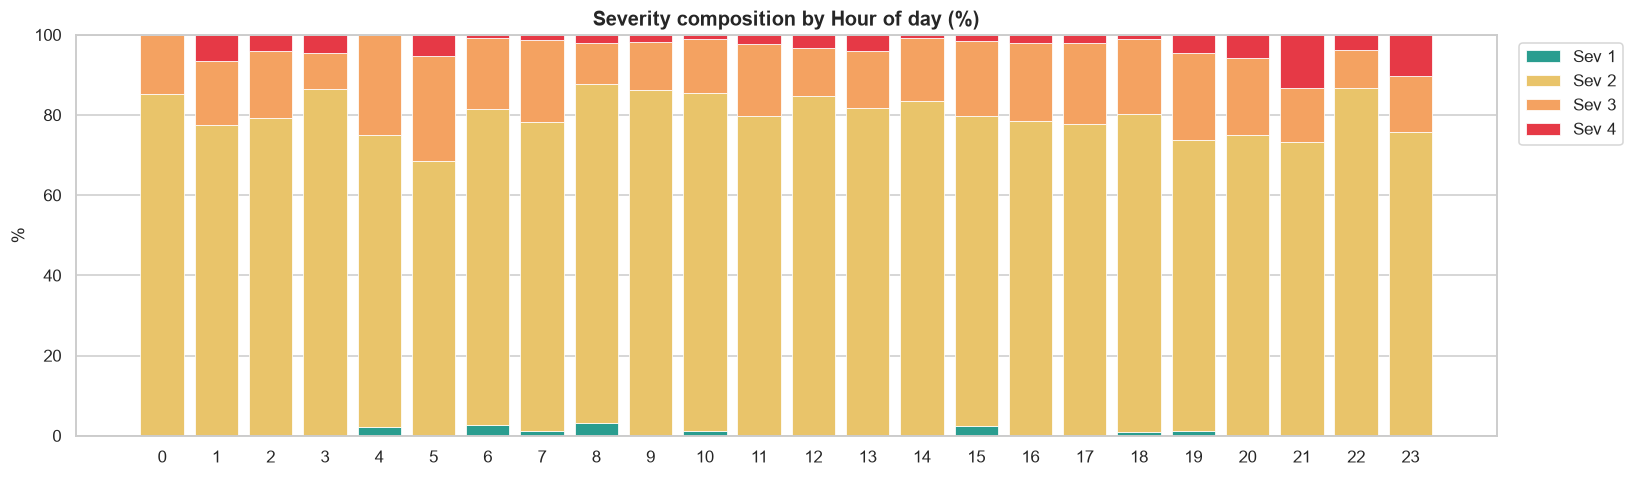

In [4]:
def sev_mix(col, order=None):
    t = pd.crosstab(df[col], df["Severity"], normalize="index") * 100
    return t.reindex(order) if order is not None else t

def stacked(ax, t, title, labels=None):
    bottom = np.zeros(len(t))
    x = labels if labels is not None else t.index.astype(str)
    for s in t.columns:
        ax.bar(x, t[s].values, bottom=bottom, color=SEV_COLORS[s], label=f"Sev {s}", edgecolor="white", lw=.5)
        bottom += t[s].values
    ax.set_title(title); ax.set_ylabel("%"); ax.set_ylim(0, 100)

fig, ax = plt.subplots(figsize=(15, 4.5))
stacked(ax, sev_mix("Hour", range(24)), "Severity composition by Hour of day (%)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

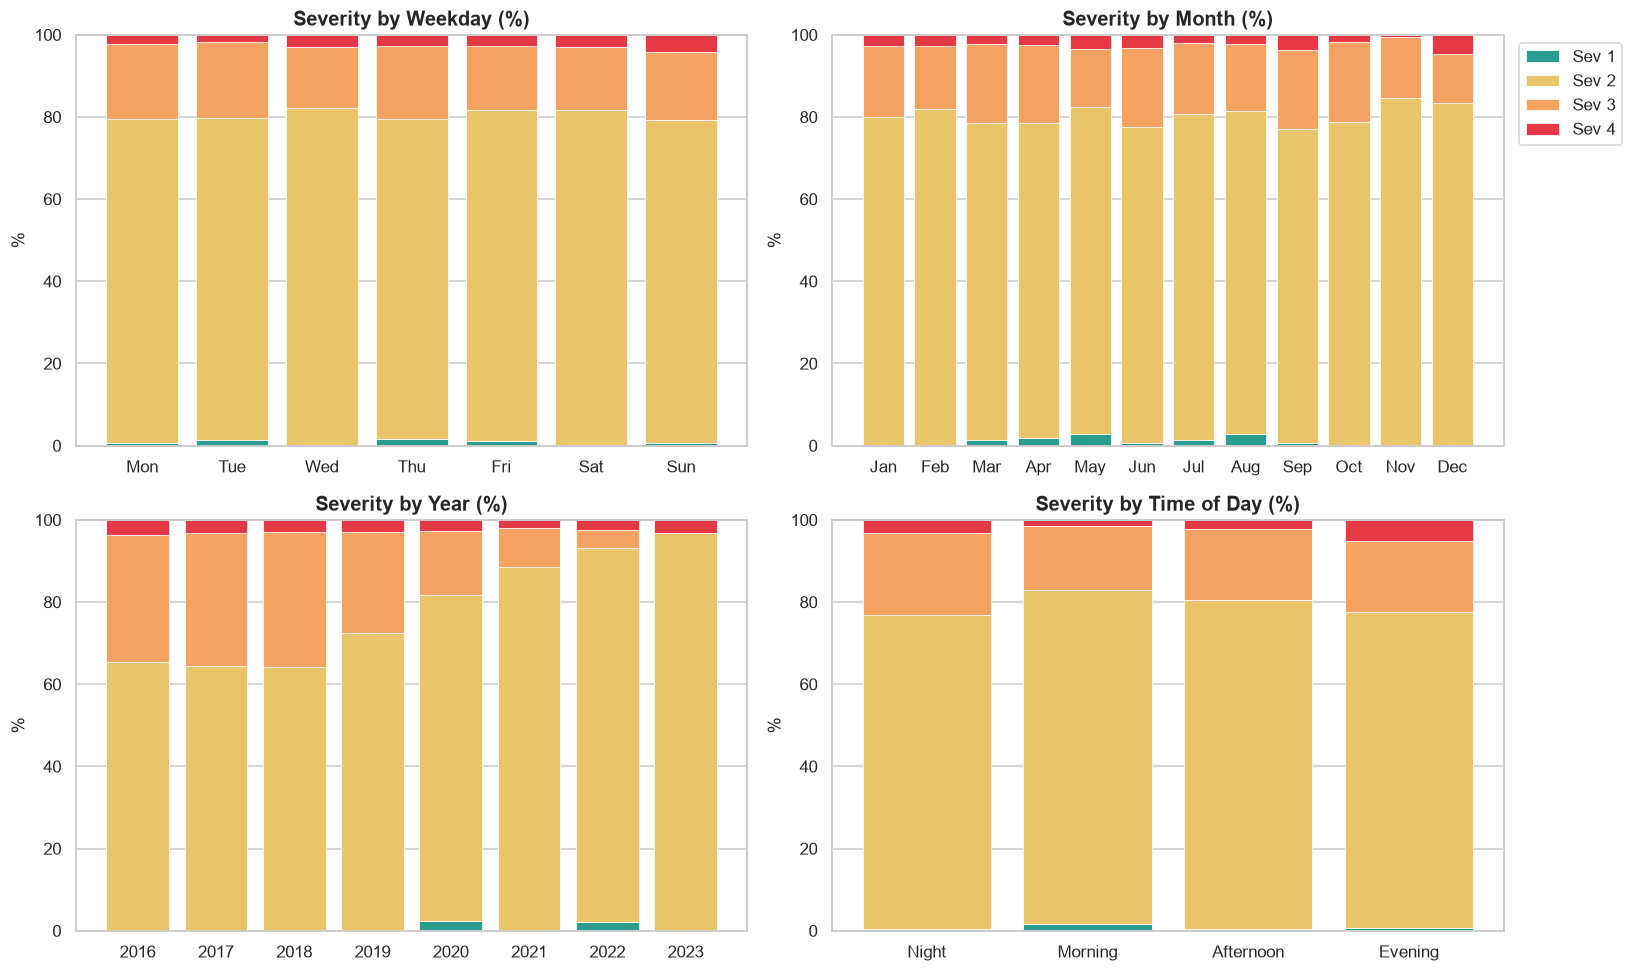

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
stacked(axes[0, 0], sev_mix("Weekday", WEEKDAYS), "Severity by Weekday (%)", [d[:3] for d in WEEKDAYS])
stacked(axes[0, 1], sev_mix("Month_Name", MONTHS), "Severity by Month (%)")
stacked(axes[1, 0], sev_mix("Year"), "Severity by Year (%)")
stacked(axes[1, 1], sev_mix("Time_of_Day", TOD), "Severity by Time of Day (%)", [t.split(" ")[0] for t in TOD])
axes[0, 1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

### Share of high-severity accidents (Severity 3–4) by time groups

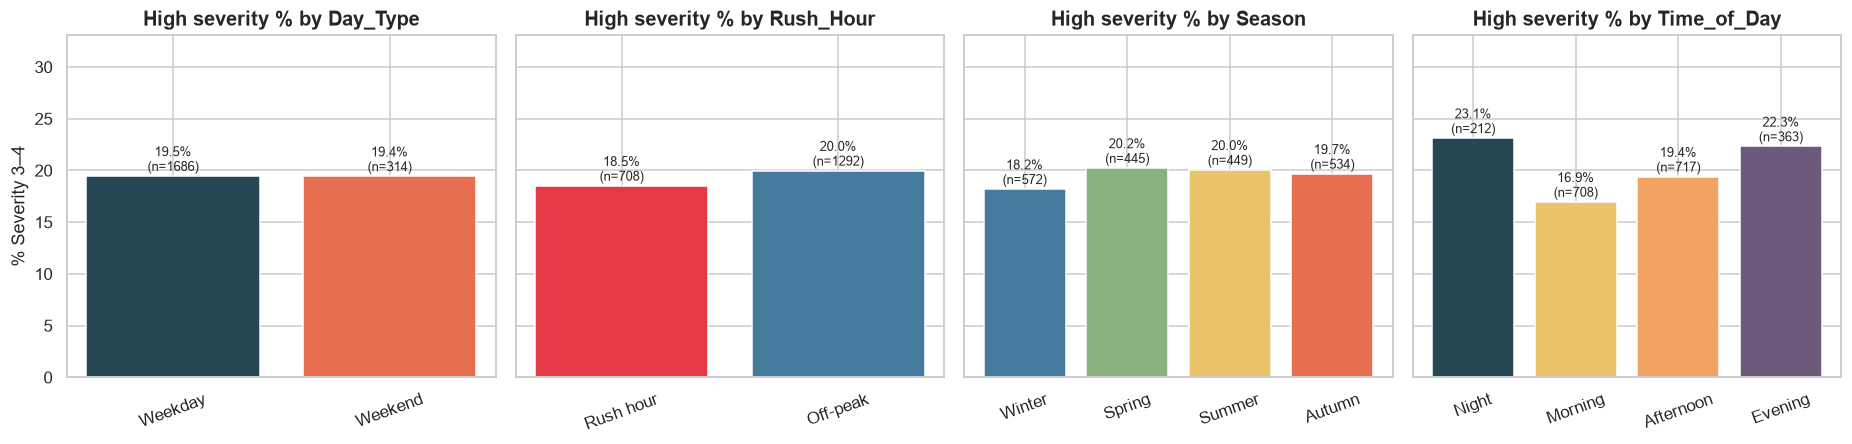

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for ax, (col, order, pal) in zip(axes, [("Day_Type", ["Weekday", "Weekend"], ["#264653", "#e76f51"]),
                                        ("Rush_Hour", ["Rush hour", "Off-peak"], ["#e63946", "#457b9d"]),
                                        ("Season", SEASONS, ["#457b9d", "#8ab17d", "#e9c46a", "#e76f51"]),
                                        ("Time_of_Day", TOD, ["#264653", "#e9c46a", "#f4a261", "#6d597a"])]):
    g = df.groupby(col, observed=True)["High_Severity"].agg(["mean", "size"]).reindex(order)
    labels = [o.split(" (")[0] for o in order]
    ax.bar(labels, g["mean"] * 100, color=pal)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m * 100 + .5, f"{m:.1%}\n(n={n})", ha="center", fontsize=8.5)
    ax.set_title(f"High severity % by {col}"); ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("% Severity 3–4")
axes[0].set_ylim(0, max(p.get_height() for a in axes for p in a.patches) + 10)
plt.tight_layout(); plt.show()

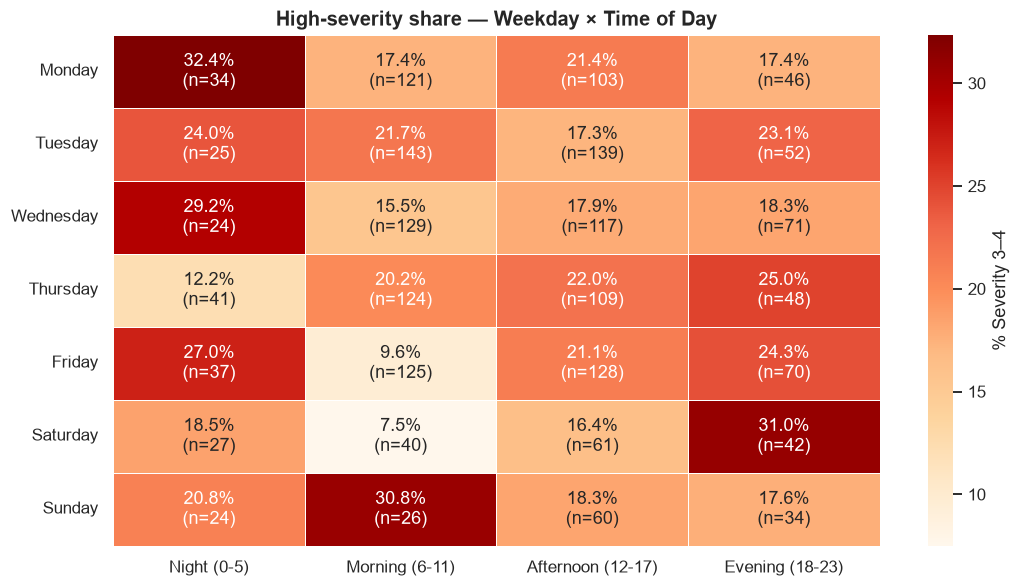

In [7]:
hm = df.pivot_table(index="Weekday", columns="Time_of_Day", values="High_Severity", aggfunc="mean", observed=False) * 100
cnt = pd.crosstab(df["Weekday"], df["Time_of_Day"]).reindex(index=WEEKDAYS, columns=TOD)
annot = hm.round(1).astype(str) + "%\n(n=" + cnt.astype(str) + ")"
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(hm.reindex(index=WEEKDAYS, columns=TOD), annot=annot.values, fmt="", cmap="OrRd",
            linewidths=.5, linecolor="white", cbar_kws={"label": "% Severity 3–4"}, ax=ax)
ax.set_title("High-severity share — Weekday × Time of Day"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 4. Time ↔ Weather
Weather has strong daily (hour) and yearly (month / season) cycles, so it is closely tied to time.

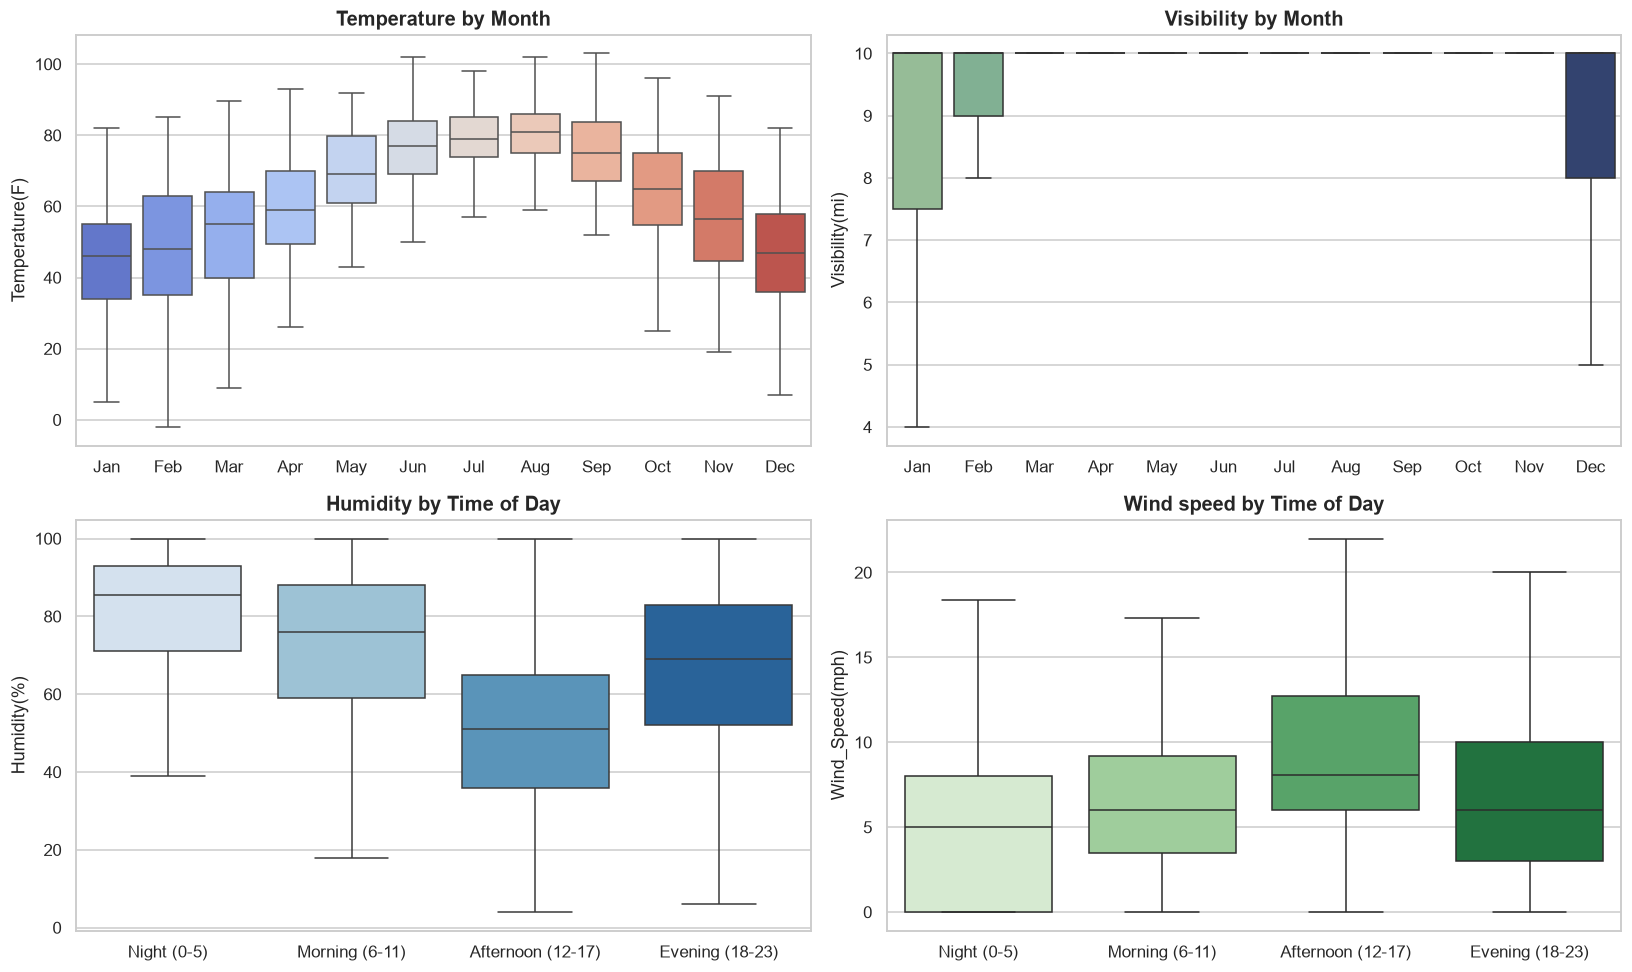

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
sns.boxplot(data=df, x="Month_Name", y="Temperature(F)", order=MONTHS, palette="coolwarm",
            showfliers=False, ax=axes[0, 0])
axes[0, 0].set_title("Temperature by Month"); axes[0, 0].set_xlabel("")
sns.boxplot(data=df, x="Month_Name", y="Visibility(mi)", order=MONTHS, palette="crest",
            showfliers=False, ax=axes[0, 1])
axes[0, 1].set_title("Visibility by Month"); axes[0, 1].set_xlabel("")
sns.boxplot(data=df, x="Time_of_Day", y="Humidity(%)", order=TOD, palette="Blues",
            showfliers=False, ax=axes[1, 0])
axes[1, 0].set_title("Humidity by Time of Day"); axes[1, 0].set_xlabel("")
sns.boxplot(data=df, x="Time_of_Day", y="Wind_Speed(mph)", order=TOD, palette="Greens",
            showfliers=False, ax=axes[1, 1])
axes[1, 1].set_title("Wind speed by Time of Day"); axes[1, 1].set_xlabel("")
plt.tight_layout(); plt.show()

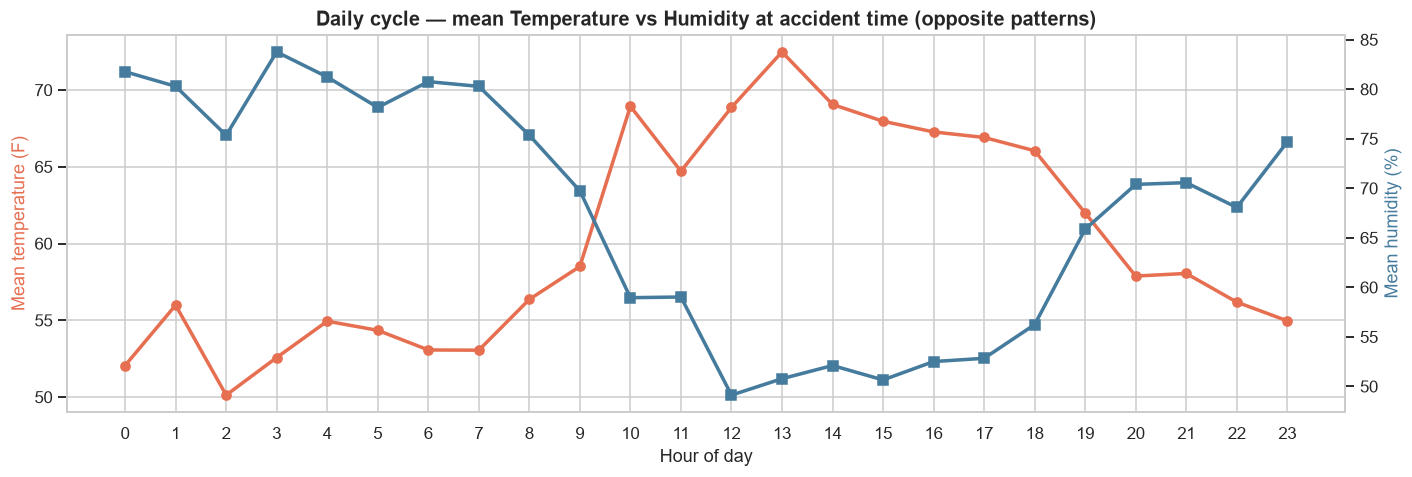

In [9]:
h = df.groupby("Hour")[["Temperature(F)", "Humidity(%)"]].mean().reindex(range(24))
fig, ax1 = plt.subplots(figsize=(13, 4.5))
ax1.plot(h.index, h["Temperature(F)"], marker="o", color="#e76f51", lw=2.3, label="Temperature (F)")
ax1.set_ylabel("Mean temperature (F)", color="#e76f51")
ax2 = ax1.twinx()
ax2.plot(h.index, h["Humidity(%)"], marker="s", color="#457b9d", lw=2.3, label="Humidity (%)")
ax2.set_ylabel("Mean humidity (%)", color="#457b9d"); ax2.grid(False)
ax1.set_xticks(range(24)); ax1.set_xlabel("Hour of day")
ax1.set_title("Daily cycle — mean Temperature vs Humidity at accident time (opposite patterns)")
plt.tight_layout(); plt.show()

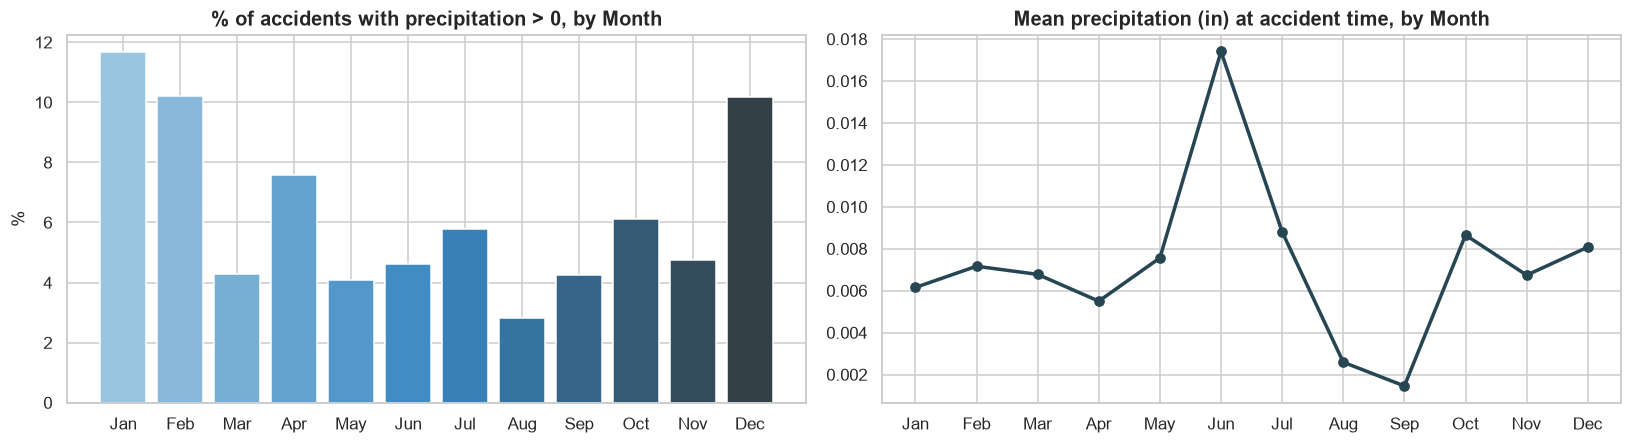

In [10]:
p = df.assign(Has_Precip=df["Precipitation(in)"] > 0)
g = p.groupby("Month_Name", observed=False).agg(precip_share=("Has_Precip", "mean"),
                                                mean_precip=("Precipitation(in)", "mean")).reindex(MONTHS)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
axes[0].bar(g.index, g["precip_share"] * 100, color=sns.color_palette("Blues_d", 12))
axes[0].set_title("% of accidents with precipitation > 0, by Month"); axes[0].set_ylabel("%")
axes[1].plot(g.index, g["mean_precip"], marker="o", color="#264653", lw=2.3)
axes[1].set_title("Mean precipitation (in) at accident time, by Month")
plt.tight_layout(); plt.show()

### Weather condition × Season and × Time of Day (column %)

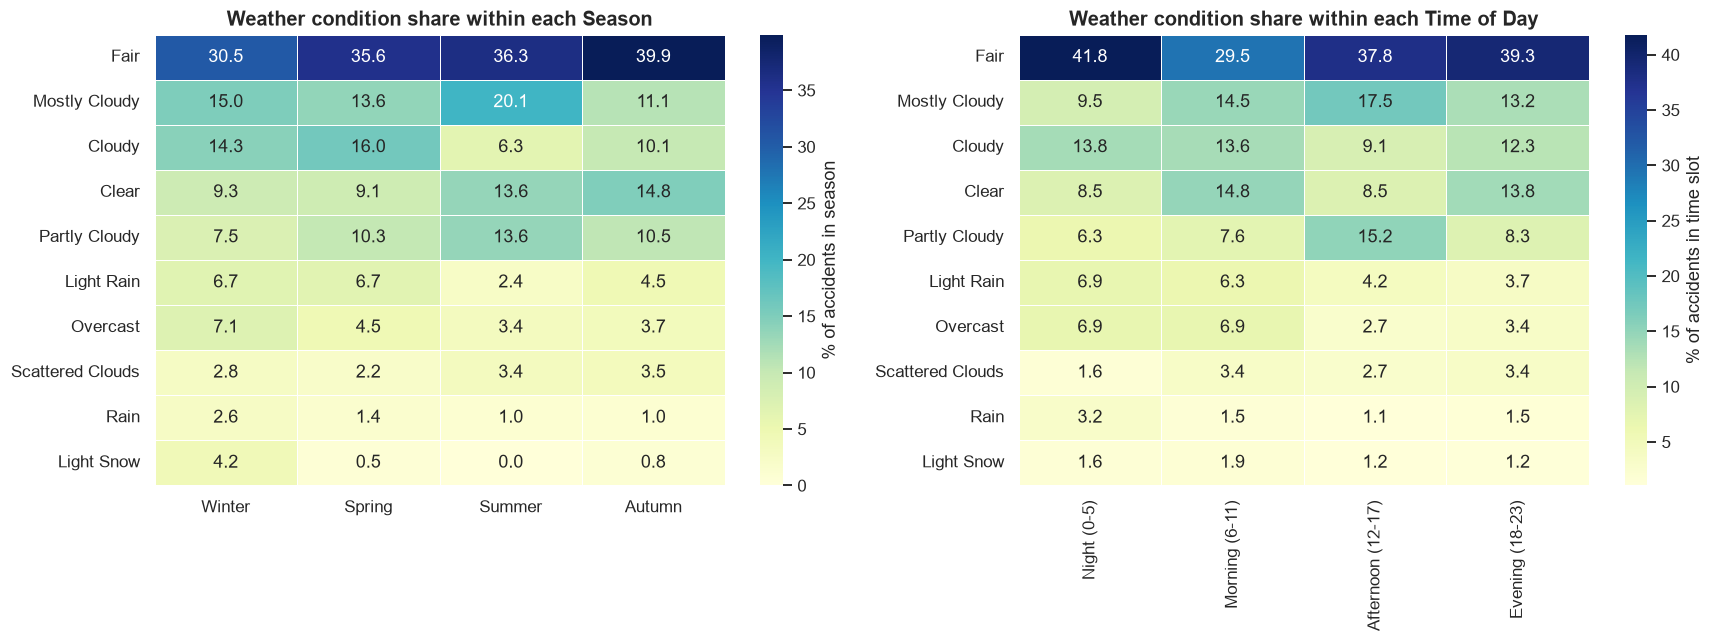

In [11]:
top_w = df["Weather_Condition"].value_counts().index[:10]
sub = df[df["Weather_Condition"].isin(top_w)]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ws = pd.crosstab(sub["Weather_Condition"], sub["Season"], normalize="columns").reindex(index=top_w, columns=SEASONS) * 100
sns.heatmap(ws, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=.5, linecolor="white",
            cbar_kws={"label": "% of accidents in season"}, ax=axes[0])
axes[0].set_title("Weather condition share within each Season"); axes[0].set_xlabel(""); axes[0].set_ylabel("")
wt = pd.crosstab(sub["Weather_Condition"], sub["Time_of_Day"], normalize="columns").reindex(index=top_w, columns=TOD) * 100
sns.heatmap(wt, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=.5, linecolor="white",
            cbar_kws={"label": "% of accidents in time slot"}, ax=axes[1])
axes[1].set_title("Weather condition share within each Time of Day"); axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

### Time alignment of the weather data
`Weather_Timestamp − Start_Time` shows how close (in time) the weather observation is to the accident.

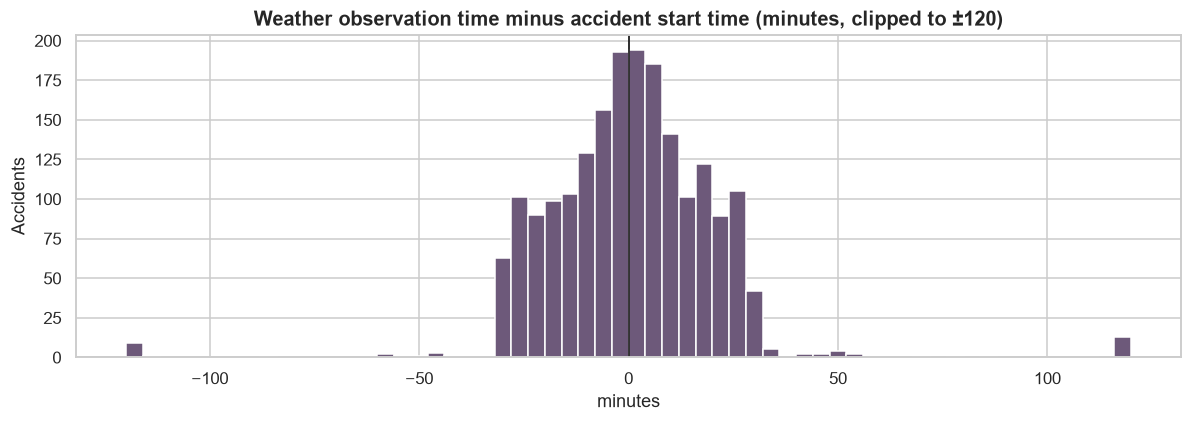

Median |lag| = 11.9 min;  within ±30 min: 96.7%;  within ±60 min: 98.5%


In [12]:
lag = df["Weather_Lag_min"].dropna()
fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(lag.clip(-120, 120), bins=60, color="#6d597a", edgecolor="white")
ax.axvline(0, color="black", lw=1)
ax.set_title("Weather observation time minus accident start time (minutes, clipped to ±120)")
ax.set_xlabel("minutes"); ax.set_ylabel("Accidents")
plt.tight_layout(); plt.show()
print(f"Median |lag| = {lag.abs().median():.1f} min;  within ±30 min: {(lag.abs() <= 30).mean():.1%};  "
      f"within ±60 min: {(lag.abs() <= 60).mean():.1%}")

## 5. Time ↔ Day / Night & Twilight
The four daylight columns are themselves time features (they depend on the hour, the date and the location).

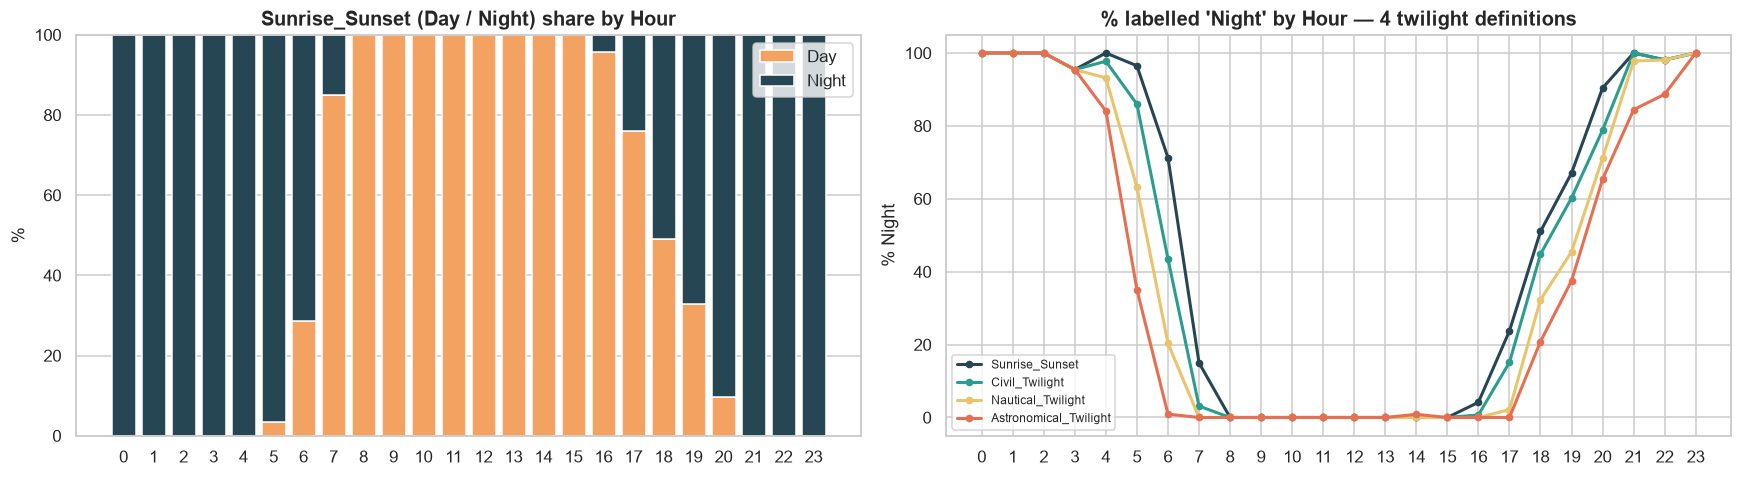

In [13]:
dn = pd.crosstab(df["Hour"], df["Sunrise_Sunset"], normalize="index").reindex(range(24)) * 100
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].bar(dn.index, dn["Day"], color="#f4a261", label="Day")
axes[0].bar(dn.index, dn["Night"], bottom=dn["Day"], color="#264653", label="Night")
axes[0].set_title("Sunrise_Sunset (Day / Night) share by Hour"); axes[0].set_xticks(range(24))
axes[0].set_ylabel("%"); axes[0].legend()

for c, col in zip(TWILIGHT_COLS, ["#264653", "#2a9d8f", "#e9c46a", "#e76f51"]):
    s = (df[c] == "Night").groupby(df["Hour"]).mean().reindex(range(24)) * 100
    axes[1].plot(s.index, s.values, marker="o", ms=4, lw=2, color=col, label=c)
axes[1].set_title("% labelled 'Night' by Hour — 4 twilight definitions"); axes[1].set_xticks(range(24))
axes[1].set_ylabel("% Night"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

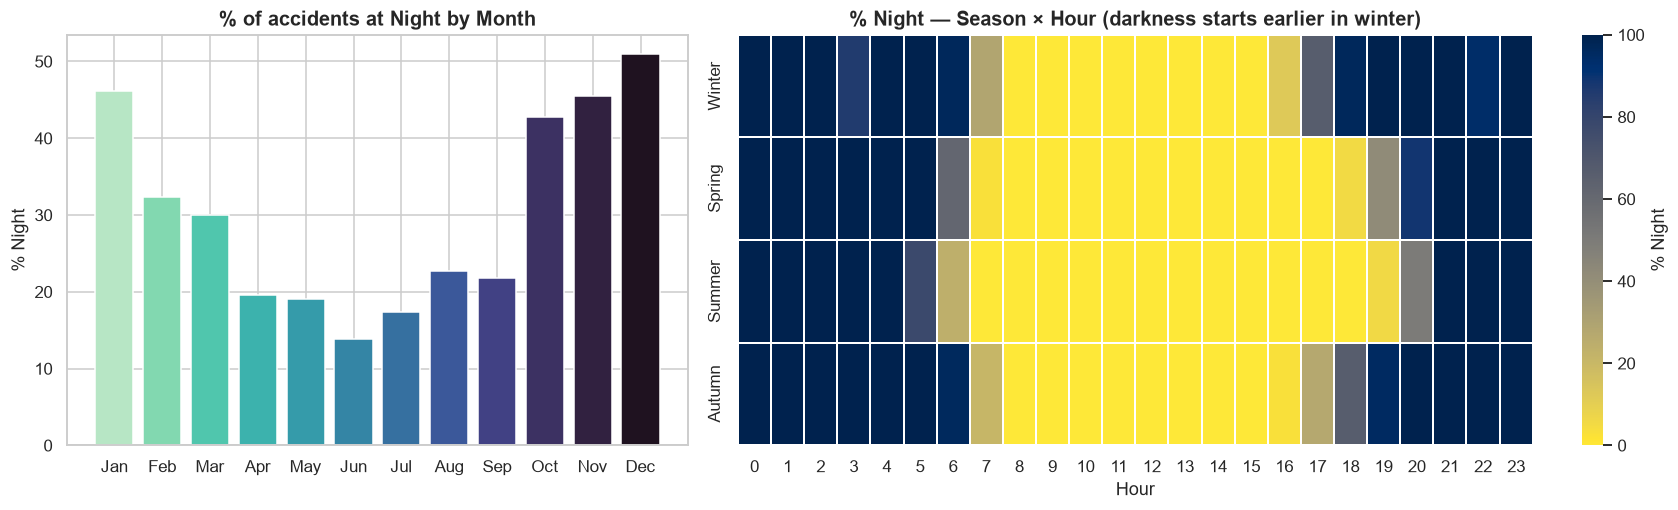

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})
nm = (df["Sunrise_Sunset"] == "Night").groupby(df["Month_Name"], observed=False).mean().reindex(MONTHS) * 100
axes[0].bar(nm.index, nm.values, color=sns.color_palette("mako_r", 12))
axes[0].set_title("% of accidents at Night by Month"); axes[0].set_ylabel("% Night")

sh = (df["Sunrise_Sunset"] == "Night").groupby([df["Season"], df["Hour"]], observed=False).mean().unstack() * 100
sh = sh.reindex(index=SEASONS, columns=range(24))
sns.heatmap(sh, cmap="cividis_r", linewidths=.3, linecolor="white", cbar_kws={"label": "% Night"}, ax=axes[1])
axes[1].set_title("% Night — Season × Hour (darkness starts earlier in winter)")
axes[1].set_xlabel("Hour"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

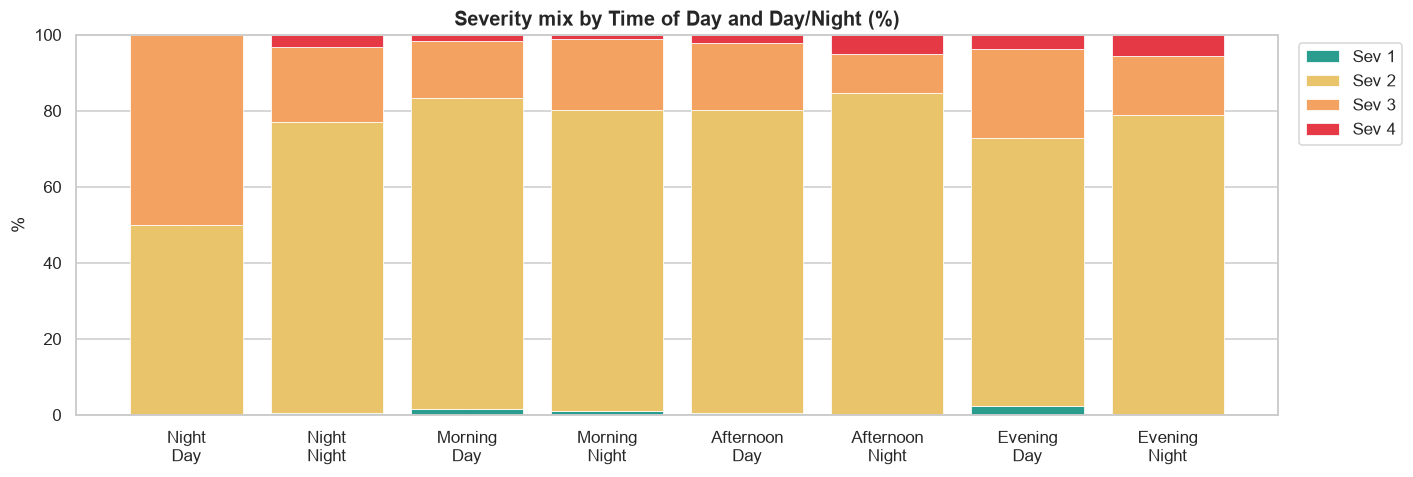

In [15]:
t = pd.crosstab([df["Time_of_Day"], df["Sunrise_Sunset"]], df["Severity"], normalize="index") * 100
fig, ax = plt.subplots(figsize=(13, 4.5))
stacked(ax, t, "Severity mix by Time of Day and Day/Night (%)",
        [f"{a.split(' ')[0]}\n{b}" for a, b in t.index])
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

## 6. Time ↔ Duration & Distance
`Duration_min = End_Time − Start_Time` is a pure time feature. We relate it (and `Distance(mi)`) to the calendar
and clock features. The data **Source** is shown too because the reporting source changes over the years
and strongly affects duration and distance.

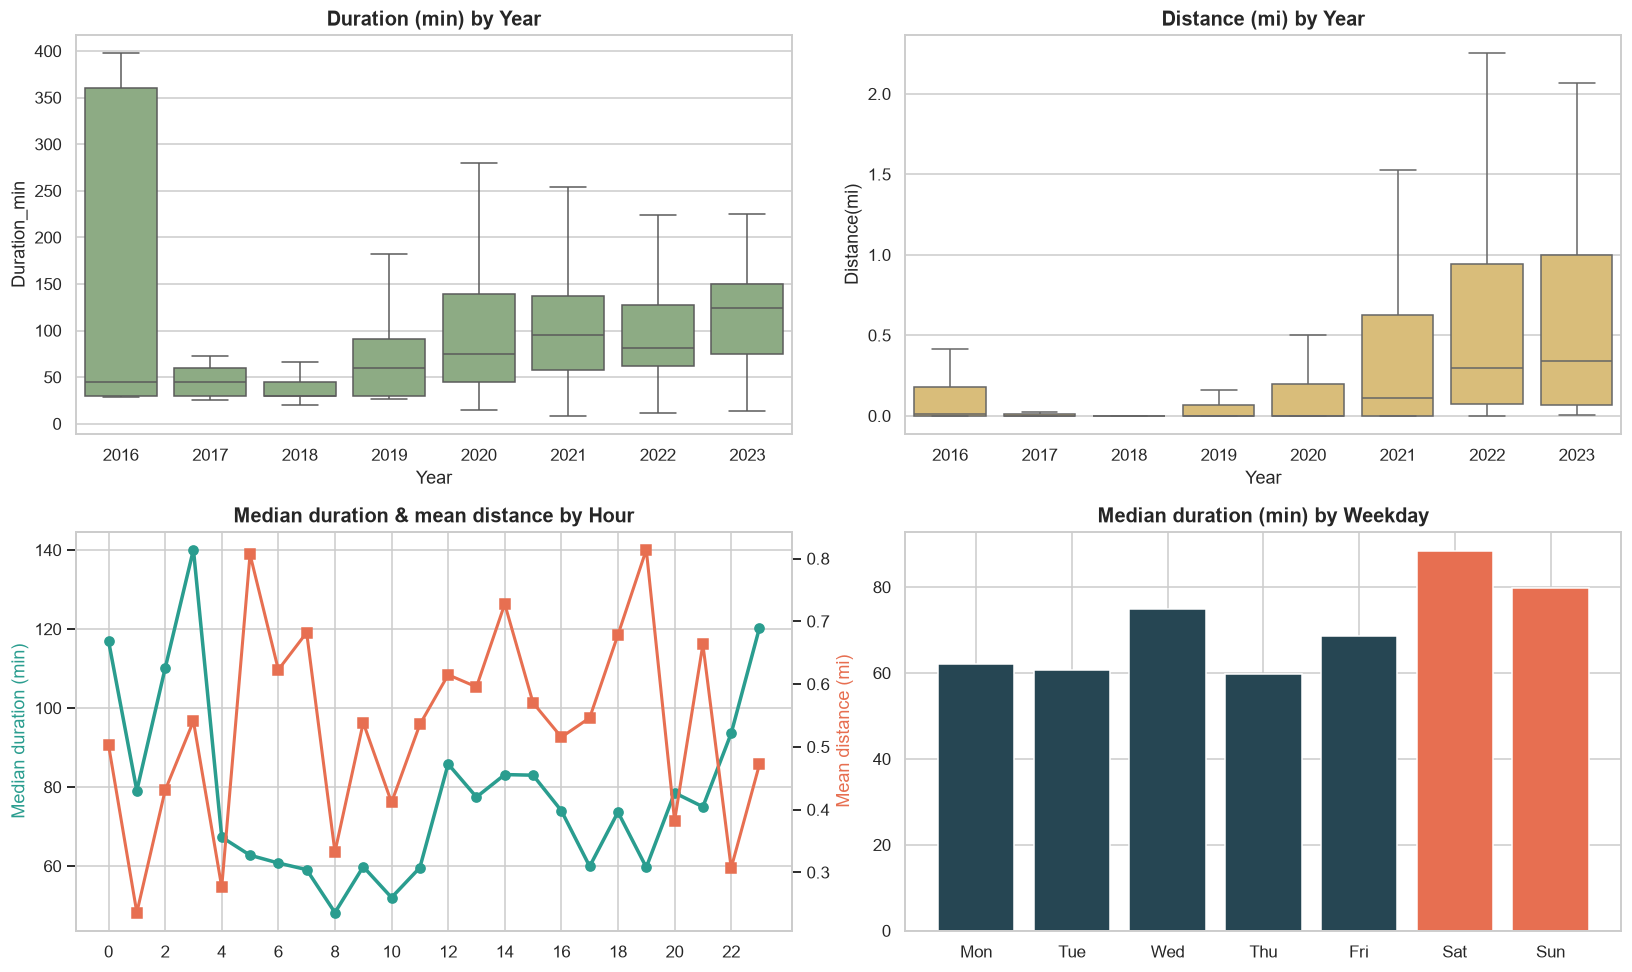

In [16]:
d = df[df["Duration_min"].between(0, 24 * 60)]
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
sns.boxplot(data=d, x="Year", y="Duration_min", color="#8ab17d", showfliers=False, ax=axes[0, 0])
axes[0, 0].set_title("Duration (min) by Year")
sns.boxplot(data=d, x="Year", y="Distance(mi)", color="#e9c46a", showfliers=False, ax=axes[0, 1])
axes[0, 1].set_title("Distance (mi) by Year")

hm = d.groupby("Hour")[["Duration_min"]].median().reindex(range(24))
hd = df.groupby("Hour")["Distance(mi)"].mean().reindex(range(24))
axes[1, 0].plot(hm.index, hm["Duration_min"], marker="o", lw=2.3, color="#2a9d8f", label="Median duration (min)")
ax2 = axes[1, 0].twinx(); ax2.grid(False)
ax2.plot(hd.index, hd.values, marker="s", lw=2, color="#e76f51", label="Mean distance (mi)")
axes[1, 0].set_title("Median duration & mean distance by Hour"); axes[1, 0].set_xticks(range(0, 24, 2))
axes[1, 0].set_ylabel("Median duration (min)", color="#2a9d8f"); ax2.set_ylabel("Mean distance (mi)", color="#e76f51")

wdm = d.groupby("Weekday", observed=False)["Duration_min"].median().reindex(WEEKDAYS)
axes[1, 1].bar([w[:3] for w in WEEKDAYS], wdm.values, color=["#264653"] * 5 + ["#e76f51"] * 2)
axes[1, 1].set_title("Median duration (min) by Weekday")
plt.tight_layout(); plt.show()

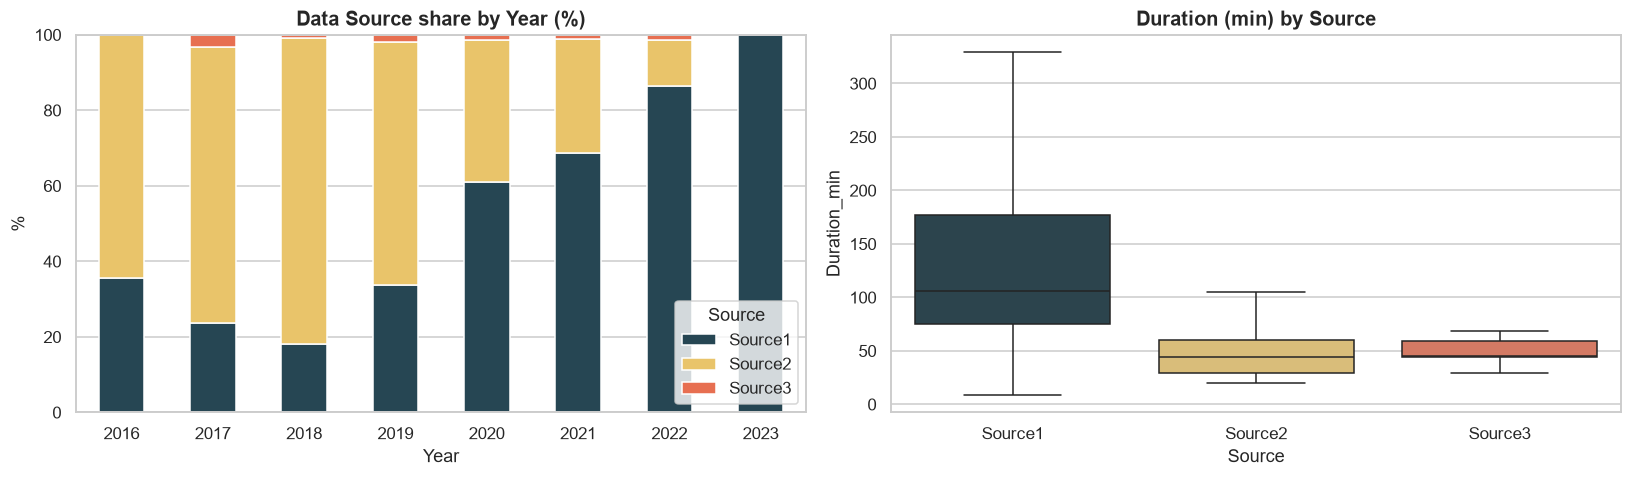

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
src = pd.crosstab(df["Year"], df["Source"], normalize="index") * 100
src.plot(kind="bar", stacked=True, ax=axes[0], color=["#264653", "#e9c46a", "#e76f51"], rot=0)
axes[0].set_title("Data Source share by Year (%)"); axes[0].set_ylabel("%"); axes[0].legend(title="Source")
sns.boxplot(data=d, x="Source", y="Duration_min", order=sorted(df["Source"].unique()),
            palette=["#264653", "#e9c46a", "#e76f51"], showfliers=False, ax=axes[1])
axes[1].set_title("Duration (min) by Source")
plt.tight_layout(); plt.show()

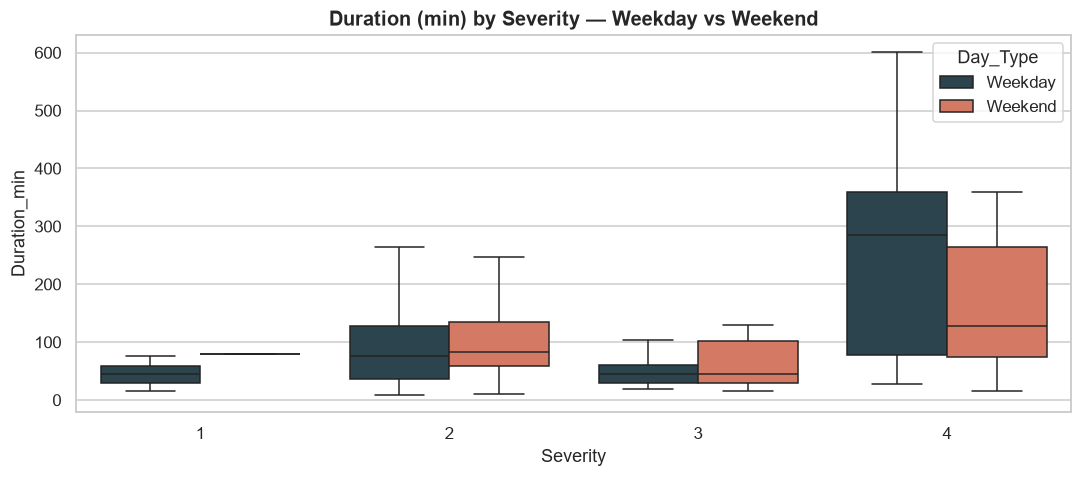

In [18]:
d2 = d.copy()
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=d2, x="Severity", y="Duration_min", hue="Day_Type", palette=["#264653", "#e76f51"],
            showfliers=False, ax=ax)
ax.set_title("Duration (min) by Severity — Weekday vs Weekend")
plt.tight_layout(); plt.show()

## 7. Time ↔ Location (Timezone, State)
All timestamps are **local time** of the `Timezone` column, so hour-of-day patterns can be compared across zones.

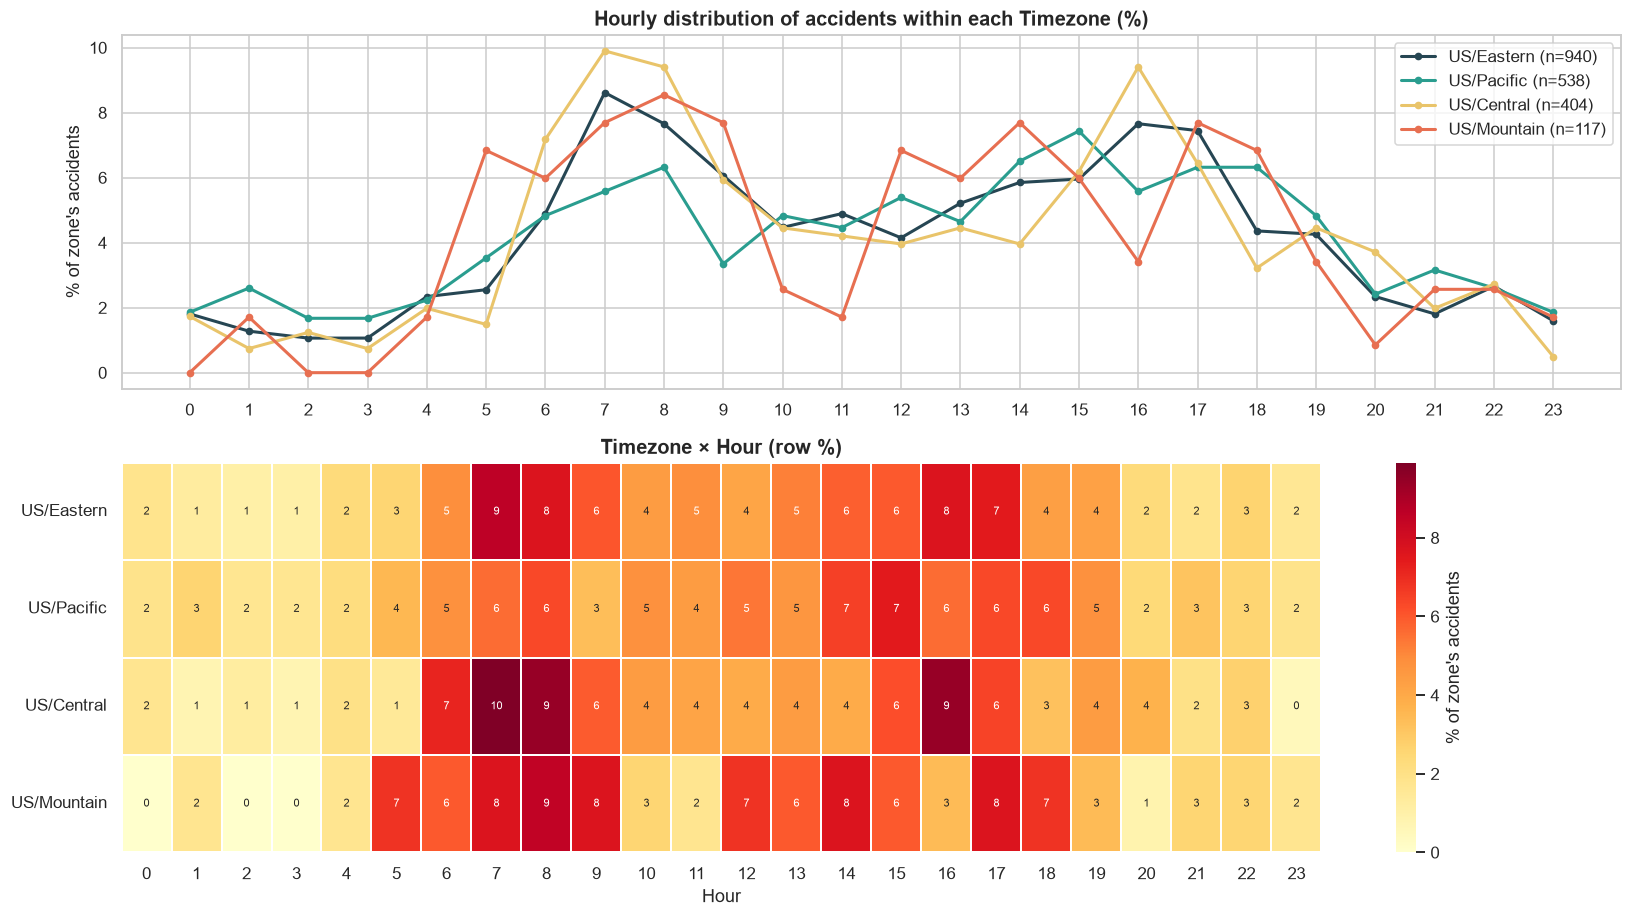

In [19]:
tz_order = df["Timezone"].value_counts().index
th = pd.crosstab(df["Timezone"], df["Hour"], normalize="index").reindex(index=tz_order, columns=range(24), fill_value=0) * 100
fig, axes = plt.subplots(2, 1, figsize=(15, 8.5), gridspec_kw={"height_ratios": [1, 1.1]})
for tz, col in zip(tz_order, ["#264653", "#2a9d8f", "#e9c46a", "#e76f51"]):
    axes[0].plot(th.columns, th.loc[tz], marker="o", ms=4, lw=2, color=col,
                 label=f"{tz} (n={(df['Timezone'] == tz).sum()})")
axes[0].set_title("Hourly distribution of accidents within each Timezone (%)")
axes[0].set_xticks(range(24)); axes[0].set_ylabel("% of zone's accidents"); axes[0].legend()
sns.heatmap(th, cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size": 7}, linewidths=.3,
            linecolor="white", cbar_kws={"label": "% of zone's accidents"}, ax=axes[1])
axes[1].set_title("Timezone × Hour (row %)"); axes[1].set_xlabel("Hour"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

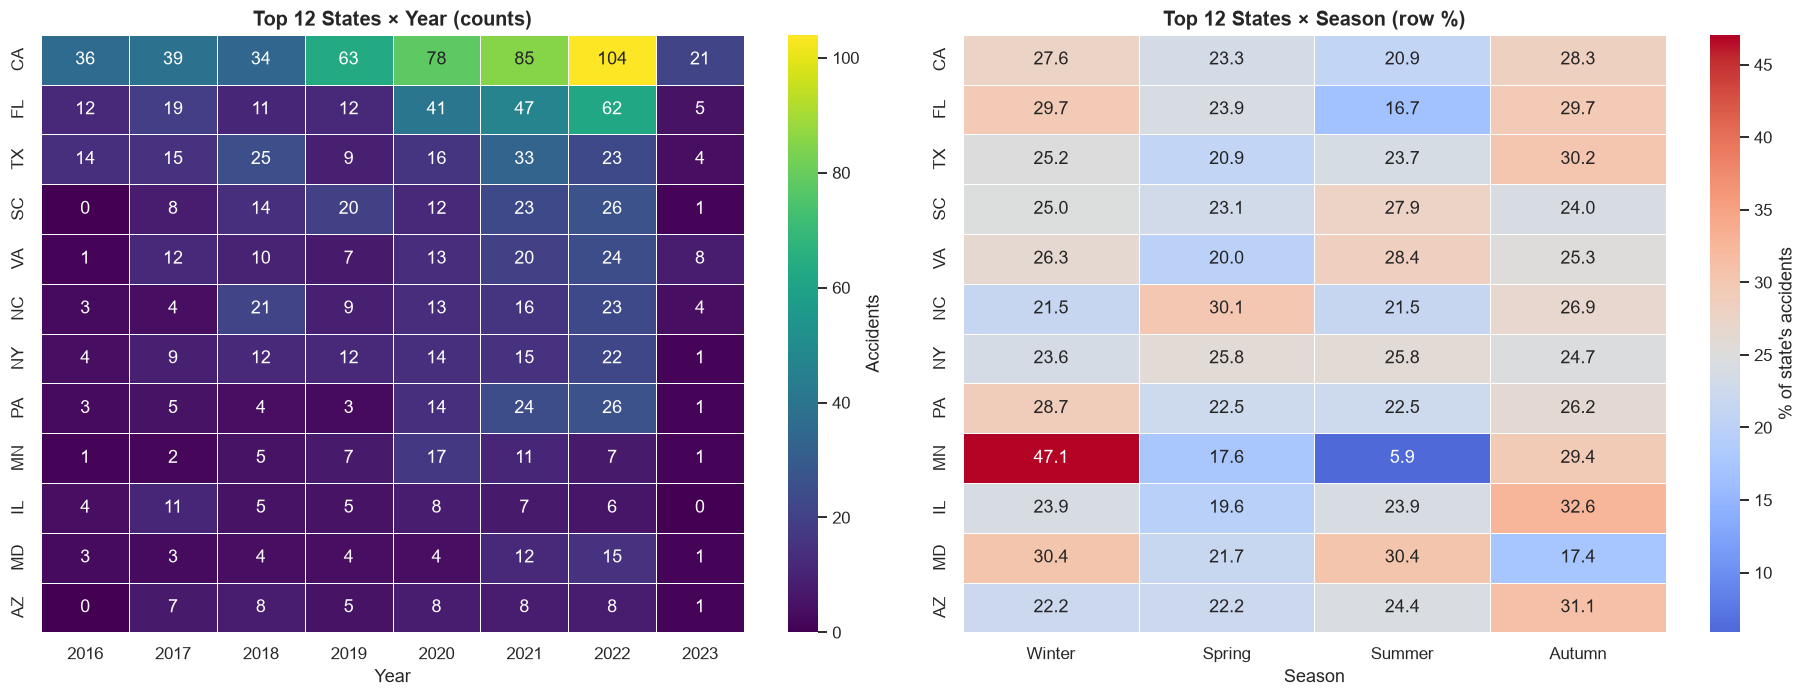

In [20]:
top_states = df["State"].value_counts().index[:12]
s = df[df["State"].isin(top_states)]
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sy = pd.crosstab(s["State"], s["Year"]).loc[top_states]
sns.heatmap(sy, annot=True, fmt="d", cmap="viridis", linewidths=.4, linecolor="white",
            cbar_kws={"label": "Accidents"}, ax=axes[0])
axes[0].set_title("Top 12 States × Year (counts)"); axes[0].set_ylabel("")
ss = pd.crosstab(s["State"], s["Season"], normalize="index").reindex(index=top_states, columns=SEASONS) * 100
sns.heatmap(ss, annot=True, fmt=".1f", cmap="coolwarm", center=25, linewidths=.4, linecolor="white",
            cbar_kws={"label": "% of state's accidents"}, ax=axes[1])
axes[1].set_title("Top 12 States × Season (row %)"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

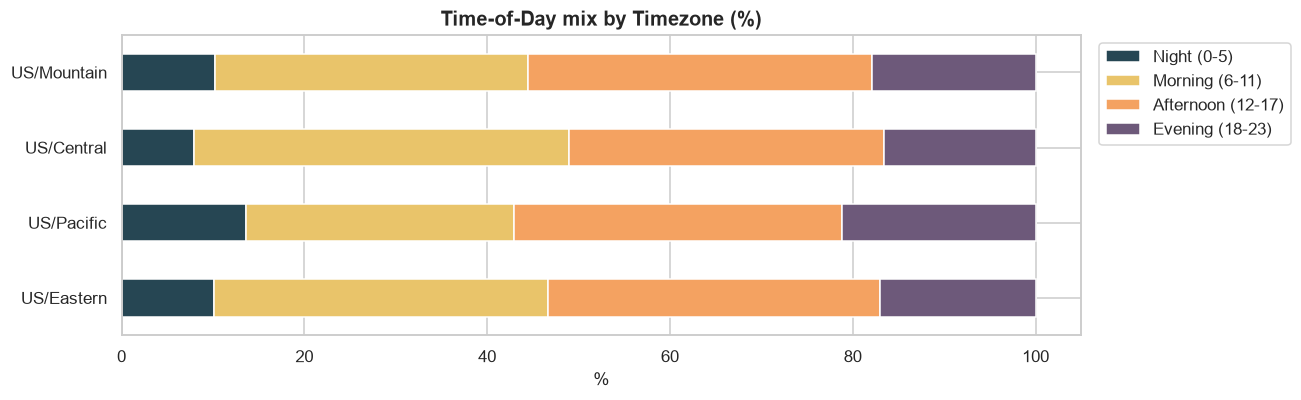

In [21]:
tt = pd.crosstab(df["Timezone"], df["Time_of_Day"], normalize="index").reindex(index=tz_order, columns=TOD) * 100
tt.plot(kind="barh", stacked=True, figsize=(12, 3.8), color=["#264653", "#e9c46a", "#f4a261", "#6d597a"])
plt.title("Time-of-Day mix by Timezone (%)"); plt.xlabel("%"); plt.ylabel("")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()

## 8. Time ↔ Road Features
Percentage of accidents that occurred near each road feature, split by time groups.

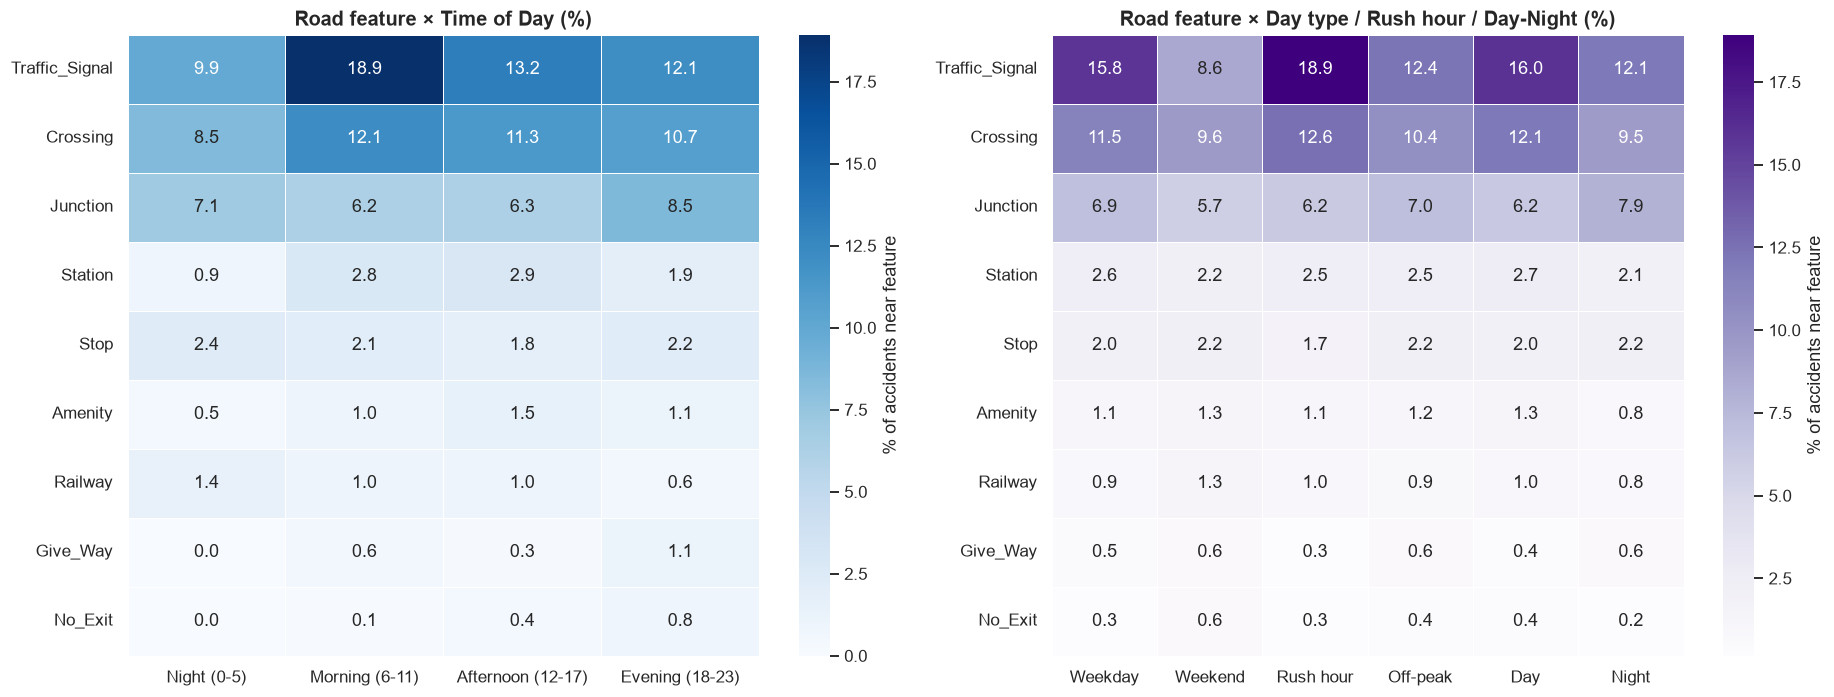

In [22]:
road = [c for c in ROAD_COLS if df[c].astype(bool).any()]   # drop features that are never True
R = df[road].astype(float)
by_tod = R.groupby(df["Time_of_Day"], observed=False).mean().T.reindex(columns=TOD) * 100
by_type = pd.concat([R.groupby(df["Day_Type"]).mean().T, R.groupby(df["Rush_Hour"]).mean().T,
                     R.groupby(df["Sunrise_Sunset"]).mean().T], axis=1) * 100
order = by_tod.mean(axis=1).sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(by_tod.loc[order], annot=True, fmt=".1f", cmap="Blues", linewidths=.5, linecolor="white",
            cbar_kws={"label": "% of accidents near feature"}, ax=axes[0])
axes[0].set_title("Road feature × Time of Day (%)"); axes[0].set_xlabel("")
sns.heatmap(by_type.loc[order, ["Weekday", "Weekend", "Rush hour", "Off-peak", "Day", "Night"]],
            annot=True, fmt=".1f", cmap="Purples", linewidths=.5, linecolor="white",
            cbar_kws={"label": "% of accidents near feature"}, ax=axes[1])
axes[1].set_title("Road feature × Day type / Rush hour / Day-Night (%)"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

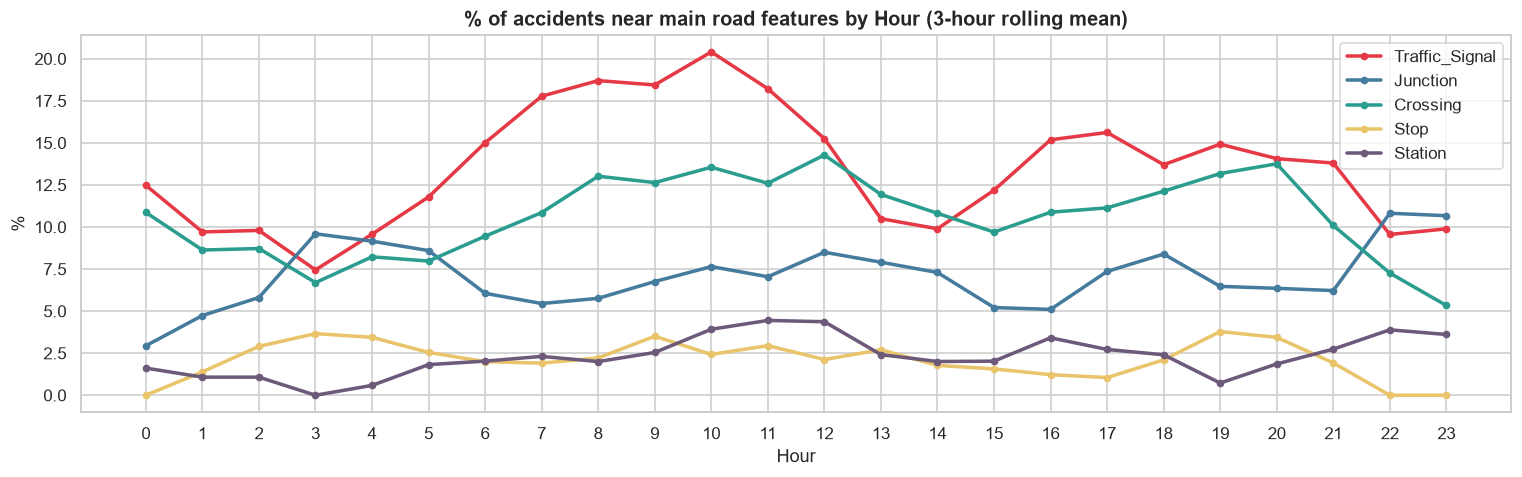

In [23]:
main = [c for c in ["Traffic_Signal", "Junction", "Crossing", "Stop", "Station"] if c in road]
hr_feat = R[main].groupby(df["Hour"]).mean().reindex(range(24)) * 100
fig, ax = plt.subplots(figsize=(14, 4.5))
for c, col in zip(main, ["#e63946", "#457b9d", "#2a9d8f", "#e9c46a", "#6d597a"]):
    ax.plot(hr_feat.index, hr_feat[c].rolling(3, center=True, min_periods=1).mean(),
            lw=2.3, marker="o", ms=4, color=col, label=c)
ax.set_title("% of accidents near main road features by Hour (3-hour rolling mean)")
ax.set_xticks(range(24)); ax.set_xlabel("Hour"); ax.set_ylabel("%"); ax.legend()
plt.tight_layout(); plt.show()

## 9. Key Findings
Computed directly from the sample.

In [24]:
hs = lambda col: df.groupby(col, observed=True)["High_Severity"].mean()
night_season = (df["Sunrise_Sunset"] == "Night").groupby(df["Season"], observed=True).mean()
temp_season = df.groupby("Season", observed=True)["Temperature(F)"].mean()
dur_year = d.groupby("Year")["Duration_min"].median()
diff = (by_type["Night"] - by_type["Day"]).sort_values()

findings = [
    f"Peak hour: {df['Hour'].value_counts().idxmax()}:00   |   peak weekday: {df['Weekday'].value_counts().idxmax()}   |   "
    f"peak month: {df['Month_Name'].value_counts().idxmax()}   |   peak year: {df['Year'].value_counts().idxmax()}",
    f"Weekend share of accidents: {(df['Day_Type'] == 'Weekend').mean():.1%} (2 of 7 days = 28.6% if uniform)",
    f"Weekday rush hours (7-9, 16-18) hold {(df['Rush_Hour'] == 'Rush hour').mean():.1%} of all accidents",
    f"High severity (3-4) — weekday {hs('Day_Type')['Weekday']:.1%} vs weekend {hs('Day_Type')['Weekend']:.1%}; "
    f"rush hour {hs('Rush_Hour')['Rush hour']:.1%} vs off-peak {hs('Rush_Hour')['Off-peak']:.1%}",
    f"Time of day with the highest high-severity share: {hs('Time_of_Day').idxmax()} ({hs('Time_of_Day').max():.1%})",
    f"Year with the highest high-severity share: {hs('Year').idxmax()} ({hs('Year').max():.1%}); "
    f"lowest: {hs('Year').idxmin()} ({hs('Year').min():.1%})",
    "Mean temperature by season: " + ", ".join(f"{k} {v:.0f}F" for k, v in temp_season.items()),
    "% of accidents at night by season: " + ", ".join(f"{k} {v:.0%}" for k, v in night_season.items()),
    f"Median duration: {dur_year.index.min()} = {dur_year.iloc[0]:.0f} min  ->  {dur_year.index.max()} = {dur_year.iloc[-1]:.0f} min",
    f"Weather observation is within ±60 min of the accident for {(lag.abs() <= 60).mean():.1%} of records",
    f"Road feature more common at night: {diff.index[-1]} (+{diff.iloc[-1]:.1f} pts); "
    f"more common by day: {diff.index[0]} ({diff.iloc[0]:.1f} pts)",
]
for i, f in enumerate(findings, 1):
    print(f"{i:2d}. {f}")

 1. Peak hour: 7:00   |   peak weekday: Friday   |   peak month: Dec   |   peak year: 2022
 2. Weekend share of accidents: 15.7% (2 of 7 days = 28.6% if uniform)
 3. Weekday rush hours (7-9, 16-18) hold 35.4% of all accidents
 4. High severity (3-4) — weekday 19.5% vs weekend 19.4%; rush hour 18.5% vs off-peak 20.0%
 5. Time of day with the highest high-severity share: Night (0-5) (23.1%)
 6. Year with the highest high-severity share: 2018 (35.8%); lowest: 2023 (3.1%)
 7. Mean temperature by season: Winter 46F, Spring 61F, Summer 79F, Autumn 65F
 8. % of accidents at night by season: Winter 44%, Spring 23%, Summer 18%, Autumn 37%
 9. Median duration: 2016 = 45 min  ->  2023 = 124 min
10. Weather observation is within ±60 min of the accident for 98.5% of records
11. Road feature more common at night: Junction (+1.7 pts); more common by day: Traffic_Signal (-3.9 pts)
